# Module 05, Part 4: The Transformer block, Vision Transformers, and what attention costs

This notebook is the runnable companion to Part 4 of the Module 05 learning
content. It checks, with code:

1. What is inside one Transformer block, and where its parameters are.
2. Where the normalization goes matters. In a 12-block stack the original
   post-norm layout fails to train without a learning-rate warmup, and the
   pre-norm layout does not.
3. A decoder block: the causal mask really blocks the future, and cross-attention
   takes its queries from one sequence and its keys and values from another.
4. A Vision Transformer: patch embedding is a convolution in disguise, and a tiny
   ViT on 8 by 8 digit images works but does not beat a plain MLP or CNN at this
   scale.
5. The bill. Attention removes the sequential bottleneck and the distance problem
   of recurrence, and replaces them with a cost that grows with the square of the
   sequence length.

Everything runs on CPU. The 12-block training runs take a few minutes.

In [1]:
import math
import time
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

INK, BODY, MUTED = "#14161B", "#4E5563", "#7C838C"
NAVY, GREEN, AMBER, KEY, RULE = "#1C3D6E", "#0E6B57", "#8A6A18", "#7A2E8A", "#D9DCE2"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": RULE, "axes.labelcolor": BODY, "xtick.color": BODY, "ytick.color": BODY,
    "axes.grid": True, "grid.color": RULE, "font.size": 10,
})

torch.manual_seed(0)
print("PyTorch version:", torch.__version__)

def causal_mask(length):
    """Boolean mask of shape (length, length). True means 'this position may be attended to'.
    Row i (the query) may look at columns 0..i (the keys), never at the future."""
    return torch.tril(torch.ones(length, length, dtype=torch.bool))


def scaled_dot_product_attention(q, k, v, mask=None, scale=True):
    """softmax(q k^T / sqrt(d_k)) v.

    q: (..., T_q, d_k)   k: (..., T_k, d_k)   v: (..., T_k, d_v)
    mask: boolean, broadcastable to (..., T_q, T_k); False entries are blocked.
    Returns (output, weights). Set scale=False to see why the scaling matters.
    """
    d_k = q.shape[-1]
    scores = q @ k.transpose(-2, -1)
    if scale:
        scores = scores / math.sqrt(d_k)
    if mask is not None:
        scores = scores.masked_fill(~mask, float("-inf"))
    weights = torch.softmax(scores, dim=-1)
    return weights @ v, weights


class MultiHeadAttention(nn.Module):
    """Several attention heads that run side by side on lower-dimensional projections.

    d_model is split into n_heads slices of size d_model // n_heads. Each head has
    its own query, key and value projection (stored together in one weight matrix
    each), attends on its own, and the head outputs are concatenated and mixed by
    a final linear layer.
    """

    def __init__(self, d_model, n_heads):
        super().__init__()
        assert d_model % n_heads == 0, "d_model must be divisible by n_heads"
        self.d_model, self.n_heads, self.d_head = d_model, n_heads, d_model // n_heads
        self.w_q = nn.Linear(d_model, d_model)
        self.w_k = nn.Linear(d_model, d_model)
        self.w_v = nn.Linear(d_model, d_model)
        self.w_o = nn.Linear(d_model, d_model)

    def split_heads(self, x):
        batch, length, _ = x.shape
        return x.view(batch, length, self.n_heads, self.d_head).transpose(1, 2)  # (batch, heads, T, d_head)

    def forward(self, x, context=None, mask=None, head_mask=None, return_weights=False):
        """x supplies the queries. context supplies keys and values (cross-attention);
        by default it is x itself (self-attention). head_mask is an optional tensor of
        shape (n_heads,) of 0/1 values used to switch individual heads off."""
        context = x if context is None else context
        q = self.split_heads(self.w_q(x))
        k = self.split_heads(self.w_k(context))
        v = self.split_heads(self.w_v(context))
        out, weights = scaled_dot_product_attention(q, k, v, mask=mask)
        if head_mask is not None:
            out = out * head_mask.view(1, -1, 1, 1)
        batch, _, length, _ = out.shape
        out = out.transpose(1, 2).reshape(batch, length, self.d_model)  # concatenate the heads
        out = self.w_o(out)
        return (out, weights) if return_weights else out


def sinusoidal_encoding(max_len, d_model):
    """Fixed encoding. Pair (2i, 2i+1) of position p holds sin and cos of p / 10000^(2i/d_model).
    Returns a tensor of shape (max_len, d_model). Needs no training and is defined for any length."""
    position = torch.arange(max_len, dtype=torch.float32).unsqueeze(1)
    freq = torch.exp(torch.arange(0, d_model, 2, dtype=torch.float32) * (-math.log(10000.0) / d_model))
    pe = torch.zeros(max_len, d_model)
    pe[:, 0::2] = torch.sin(position * freq)
    pe[:, 1::2] = torch.cos(position * freq)
    return pe


class LearnedPositions(nn.Module):
    """One trainable vector per position, up to max_len. Positions beyond max_len do not exist."""

    def __init__(self, max_len, d_model):
        super().__init__()
        self.table = nn.Embedding(max_len, d_model)

    def forward(self, length):
        return self.table(torch.arange(length, device=self.table.weight.device))


class FeedForward(nn.Module):
    """The position-wise network: two linear layers with a nonlinearity between them,
    applied to every position independently."""

    def __init__(self, d_model, d_ff):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_model, d_ff), nn.GELU(), nn.Linear(d_ff, d_model))

    def forward(self, x):
        return self.net(x)


class TransformerBlock(nn.Module):
    """One encoder block: self-attention, then a feed-forward network, each wrapped in a residual path.

    norm='pre'  : x = x + sublayer(LayerNorm(x))   (normalize on the branch, residual path stays clean)
    norm='post' : x = LayerNorm(x + sublayer(x))   (normalize after the addition, as in the original design)
    causal=True blocks attention to future positions, which turns the block into a decoder-style block.
    """

    def __init__(self, d_model, n_heads, d_ff, norm="pre", causal=False):
        super().__init__()
        assert norm in ("pre", "post")
        self.norm_type, self.causal = norm, causal
        self.attn = MultiHeadAttention(d_model, n_heads)
        self.ff = FeedForward(d_model, d_ff)
        self.ln1, self.ln2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)

    def forward(self, x, head_mask=None, return_weights=False):
        mask = causal_mask(x.shape[1]).to(x.device) if self.causal else None
        weights = None
        if self.norm_type == "pre":
            a = self.attn(self.ln1(x), mask=mask, head_mask=head_mask, return_weights=return_weights)
            a, weights = a if return_weights else (a, None)
            x = x + a
            x = x + self.ff(self.ln2(x))
        else:
            a = self.attn(x, mask=mask, head_mask=head_mask, return_weights=return_weights)
            a, weights = a if return_weights else (a, None)
            x = self.ln1(x + a)
            x = self.ln2(x + self.ff(x))
        return (x, weights) if return_weights else x


class DecoderBlock(nn.Module):
    """A decoder block: masked self-attention, cross-attention to the encoder output, then feed-forward.
    Pre-norm layout. The cross-attention takes its queries from the decoder and its keys and values from the encoder."""

    def __init__(self, d_model, n_heads, d_ff):
        super().__init__()
        self.self_attn = MultiHeadAttention(d_model, n_heads)
        self.cross_attn = MultiHeadAttention(d_model, n_heads)
        self.ff = FeedForward(d_model, d_ff)
        self.ln1, self.ln2, self.ln3 = nn.LayerNorm(d_model), nn.LayerNorm(d_model), nn.LayerNorm(d_model)

    def forward(self, x, memory):
        x = x + self.self_attn(self.ln1(x), mask=causal_mask(x.shape[1]).to(x.device))
        x = x + self.cross_attn(self.ln2(x), context=memory)
        return x + self.ff(self.ln3(x))


class SequenceClassifier(nn.Module):
    """Token embedding, optional positional encoding, a stack of encoder blocks, mean pooling, a linear head.

    pos: 'none', 'learned' or 'sinusoidal'. For 'learned', max_len fixes how many positions exist.
    inputs: integer token ids of shape (batch, T).
    """

    def __init__(self, vocab, n_classes, d_model=32, n_heads=4, d_ff=64, n_layers=2,
                 pos="sinusoidal", max_len=64, norm="pre"):
        super().__init__()
        self.pos_kind, self.d_model = pos, d_model
        self.embed = nn.Embedding(vocab, d_model)
        if pos == "learned":
            self.pos = LearnedPositions(max_len, d_model)
        elif pos == "sinusoidal":
            self.register_buffer("pe", sinusoidal_encoding(max_len, d_model))
        self.blocks = nn.ModuleList([TransformerBlock(d_model, n_heads, d_ff, norm=norm) for _ in range(n_layers)])
        self.final_norm = nn.LayerNorm(d_model) if norm == "pre" else nn.Identity()
        self.head = nn.Linear(d_model, n_classes)

    def encode(self, tokens, head_mask=None):
        x = self.embed(tokens)
        length = tokens.shape[1]
        if self.pos_kind == "learned":
            x = x + self.pos(length)
        elif self.pos_kind == "sinusoidal":
            x = x + self.pe[:length]
        for block in self.blocks:
            x = block(x, head_mask=head_mask)
        return self.final_norm(x)

    def forward(self, tokens, head_mask=None):
        return self.head(self.encode(tokens, head_mask).mean(dim=1))


def patchify(images, patch):
    """Cut a batch of images (B, C, H, W) into non-overlapping square patches and flatten each one.
    Returns (B, n_patches, C * patch * patch). Patches are read left to right, top to bottom."""
    b, c, h, w = images.shape
    assert h % patch == 0 and w % patch == 0, "image size must be divisible by the patch size"
    x = images.unfold(2, patch, patch).unfold(3, patch, patch)       # (B, C, H/p, W/p, p, p)
    x = x.permute(0, 2, 3, 1, 4, 5).reshape(b, (h // patch) * (w // patch), c * patch * patch)
    return x


class PatchEmbedding(nn.Module):
    """Flatten each patch and map it to d_model with one shared linear layer."""

    def __init__(self, patch, in_channels, d_model):
        super().__init__()
        self.patch = patch
        self.proj = nn.Linear(in_channels * patch * patch, d_model)

    def forward(self, images):
        return self.proj(patchify(images, self.patch))


class TinyViT(nn.Module):
    """Patch embedding, a learned class token, learned position embeddings, encoder blocks, linear head on the class token."""

    def __init__(self, img_size=8, patch=2, in_channels=1, n_classes=10, d_model=32,
                 n_heads=4, d_ff=64, n_layers=2, norm="pre"):
        super().__init__()
        n_patches = (img_size // patch) ** 2
        self.embed = PatchEmbedding(patch, in_channels, d_model)
        self.cls = nn.Parameter(torch.zeros(1, 1, d_model))
        self.pos = nn.Parameter(torch.randn(1, n_patches + 1, d_model) * 0.02)
        self.blocks = nn.ModuleList([TransformerBlock(d_model, n_heads, d_ff, norm=norm) for _ in range(n_layers)])
        self.norm = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, n_classes)

    def forward(self, images):
        x = self.embed(images)
        x = torch.cat([self.cls.expand(x.shape[0], -1, -1), x], dim=1) + self.pos
        for block in self.blocks:
            x = block(x)
        return self.head(self.norm(x)[:, 0])

PyTorch version: 2.10.0+cpu


## 1. One block

A block is two sub-layers, each wrapped in a **residual connection**: multi-head
self-attention, then a position-wise feed-forward network (the same small MLP
applied to every position independently). Attention is the only place positions
talk to each other; the feed-forward network is where each position is processed
on its own.

In [2]:
d_model, n_heads = 32, 4
d_ff = 4 * d_model                        # the usual choice: the hidden layer is four times as wide
block = TransformerBlock(d_model, n_heads, d_ff)
x = torch.randn(3, 10, d_model)
print("input shape:", tuple(x.shape), " output shape:", tuple(block(x).shape), "(a block never changes the shape)")

count = lambda m: sum(p.numel() for p in m.parameters())
print(f"attention parameters:    {count(block.attn):6d}")
print(f"feed-forward parameters: {count(block.ff):6d}")
print(f"layer-norm parameters:   {count(block.ln1) + count(block.ln2):6d}")
print(f"whole block:             {count(block):6d}")

input shape: (3, 10, 32)  output shape: (3, 10, 32) (a block never changes the shape)
attention parameters:      4224
feed-forward parameters:   8352
layer-norm parameters:      128
whole block:              12704


With the usual hidden width of four times `d_model`, the feed-forward network holds
about two thirds of the block's parameters. Attention decides what to gather; the
feed-forward network decides what to do with it.

## 2. Where does the normalization go?

Two layouts, with the same ingredients:

- **Post-norm** (the original design): $x \leftarrow \text{LayerNorm}(x + \text{sublayer}(x))$.
  The normalization sits **on** the residual path, so every block rescales the
  signal that is supposed to flow straight through.
- **Pre-norm**: $x \leftarrow x + \text{sublayer}(\text{LayerNorm}(x))$. The
  normalization sits on the branch, and the residual path is left untouched.

First look at the gradient reaching each block at initialization, in a 12-block
stack on the order task from Part 3 (median over five seeds).

In [3]:
def make_order_batch(batch_size, seq_len, generator, vocab=10):
    """Order task. Every sequence contains the marker tokens 1 and 2 exactly once, the rest is
    random filler from 3..vocab-1. The label is 1 if marker 1 comes before marker 2, else 0.
    The two classes contain exactly the same tokens, so only the order separates them."""
    tokens = torch.randint(3, vocab, (batch_size, seq_len), generator=generator)
    pos = torch.stack([torch.randperm(seq_len, generator=generator)[:2] for _ in range(batch_size)])
    rows = torch.arange(batch_size)
    tokens[rows, pos[:, 0]] = 1
    tokens[rows, pos[:, 1]] = 2
    labels = (pos[:, 0] < pos[:, 1]).long()
    return tokens, labels

post-norm  gradient norm in blocks 1, 6, 12: 0.398, 0.402, 0.565   last / first = 1.42
 pre-norm  gradient norm in blocks 1, 6, 12: 0.312, 0.326, 0.323   last / first = 1.03


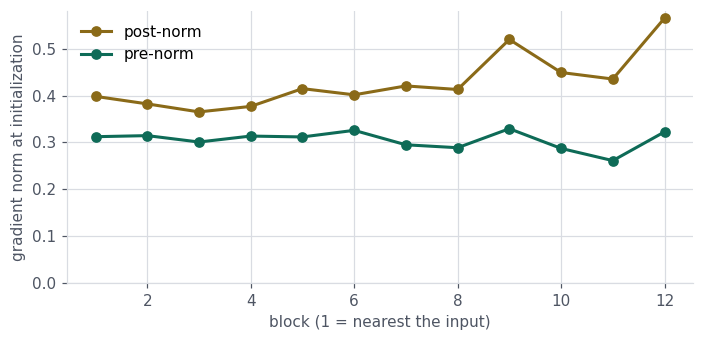

In [4]:
def block_gradients(norm, depth=12, seed=0):
    torch.manual_seed(seed)
    model = SequenceClassifier(10, 2, d_model=32, n_heads=4, d_ff=64, n_layers=depth,
                               pos="sinusoidal", max_len=32, norm=norm)
    x, y = make_order_batch(64, 16, torch.Generator().manual_seed(1))
    F.cross_entropy(model(x), y).backward()
    return [torch.sqrt(sum(p.grad.pow(2).sum() for p in b.parameters())).item() for b in model.blocks]

grads = {n: torch.tensor([block_gradients(n, seed=s) for s in range(5)]).median(0).values for n in ("post", "pre")}
for n, g in grads.items():
    print(f"{n:>4s}-norm  gradient norm in blocks 1, 6, 12: {g[0]:.3f}, {g[5]:.3f}, {g[-1]:.3f}   last / first = {(g[-1] / g[0]).item():.2f}")

plt.figure(figsize=(6.5, 3.2))
plt.plot(range(1, 13), grads["post"], color=AMBER, lw=2, marker="o", label="post-norm")
plt.plot(range(1, 13), grads["pre"], color=GREEN, lw=2, marker="o", label="pre-norm")
plt.xlabel("block (1 = nearest the input)"); plt.ylabel("gradient norm at initialization")
plt.ylim(0); plt.legend(frameon=False); plt.tight_layout(); plt.show()

At initialization the difference is modest: post-norm gradients are somewhat
larger near the output than near the input, while pre-norm gradients are almost
flat across the stack. A modest imbalance at step 0 is not obviously fatal, so the
real test is training. We train both layouts on the order task at two depths, with
and without a linear learning-rate warmup (the first 100 updates ramp the
learning rate up from near zero), three seeds each, learning rate $3 \times 10^{-3}$.

In [5]:
def train_stack(norm, depth, warmup, seed, steps=400, T=16, lr=3e-3):
    torch.manual_seed(seed)
    gen = torch.Generator().manual_seed(seed + 100)
    model = SequenceClassifier(10, 2, d_model=32, n_heads=4, d_ff=64, n_layers=depth,
                               pos="sinusoidal", max_len=32, norm=norm)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for step in range(steps):
        for group in opt.param_groups:
            group["lr"] = lr * min(1.0, (step + 1) / warmup) if warmup else lr
        x, y = make_order_batch(64, T, gen)
        loss = F.cross_entropy(model(x), y)
        opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
    xv, yv = make_order_batch(1000, T, torch.Generator().manual_seed(999))
    with torch.no_grad():
        return (model(xv).argmax(1) == yv).float().mean().item()

stack_results = {}
print(f"{'blocks':>7s} {'layout':>6s} {'warmup':>7s}   accuracy for seeds 0, 1, 2   (chance is 0.50)")
for depth in (2, 12):
    for norm in ("post", "pre"):
        for warmup in (0, 100):
            if depth == 2 and warmup == 100:
                continue                                     # the shallow control only needs the no-warmup case
            accs = [train_stack(norm, depth, warmup, s) for s in range(3)]
            stack_results[(depth, norm, warmup)] = accs
            print(f"{depth:7d} {norm:>6s} {warmup:7d}   {[round(a, 3) for a in accs]}")

 blocks layout  warmup   accuracy for seeds 0, 1, 2   (chance is 0.50)
      2   post       0   [1.0, 1.0, 1.0]
      2    pre       0   [1.0, 1.0, 1.0]
     12   post       0   [0.552, 0.552, 0.448]
     12   post     100   [1.0, 1.0, 1.0]
     12    pre       0   [1.0, 1.0, 1.0]
     12    pre     100   [1.0, 1.0, 1.0]


The pattern is clean. At 2 blocks the layout does not matter. At 12 blocks, the
post-norm stack **without warmup stays at chance** on every seed; the same stack
**with warmup** trains, and the pre-norm stack trains with or without it. Pre-norm
does not make the model better; it makes it **easier to train**, by leaving a clean
path for the signal and the gradient.

An honest qualifier: this is one small task, one learning rate and 400 updates.
Post-norm models are used successfully at large scale with careful warmup and
tuning. The lesson is that normalization placement is a training-stability
decision, and warmup is part of the recipe for the original layout.

## 3. The decoder side

A decoder block adds two things to the encoder block. Its self-attention is
**causal**, so a position cannot see later positions. And it has a second
attention layer, **cross-attention**, whose queries come from the decoder and whose
keys and values come from the encoder's output.

First, check the mask: if we change a *later* token, the outputs at earlier
positions must not move.

In [6]:
torch.manual_seed(0)
causal_block = TransformerBlock(32, 4, 64, causal=True)
x = torch.randn(1, 10, 32)
x_changed = x.clone()
x_changed[0, 7:] = torch.randn(3, 32)                  # change the last three positions only

a, b = causal_block(x), causal_block(x_changed)
print("outputs at positions 0 to 6 unchanged:", torch.allclose(a[:, :7], b[:, :7], atol=1e-6))
print("outputs at positions 7 to 9 changed:  ", not torch.allclose(a[:, 7:], b[:, 7:], atol=1e-6))

plain = TransformerBlock(32, 4, 64, causal=False)
print("without the mask, earlier positions DO see the change:",
      not torch.allclose(plain(x)[:, :7], plain(x_changed)[:, :7], atol=1e-6))

outputs at positions 0 to 6 unchanged: True
outputs at positions 7 to 9 changed:   True
without the mask, earlier positions DO see the change: True


In [7]:
torch.manual_seed(0)
decoder = DecoderBlock(32, 4, 64)
memory = torch.randn(2, 9, 32)                          # encoder output: 9 positions
target = torch.randn(2, 5, 32)                          # decoder input: 5 positions
print("decoder output shape:", tuple(decoder(target, memory).shape), " (one vector per decoder position)")

_, cross_weights = decoder.cross_attn(target, context=memory, return_weights=True)
print("cross-attention weights (batch, heads, decoder positions, encoder positions):", tuple(cross_weights.shape))

decoder output shape: (2, 5, 32)  (one vector per decoder position)
cross-attention weights (batch, heads, decoder positions, encoder positions): (2, 4, 5, 9)


The cross-attention table is $5 \times 9$: each of the 5 decoder positions
chooses how to blend the 9 encoder positions. That is how a decoder consults a
source sequence, and it is the same operation as everything else in this module
with queries and keys coming from different places.

## 4. Vision Transformers: an image is a short sequence of patches

A Transformer takes a sequence of vectors. To use one on an image, cut it into
non-overlapping square **patches**, flatten each patch, and map each flat patch to
`d_model` with one shared linear layer. The result is a sequence of patch
embeddings; from there it is the same encoder as before, plus a learned class token
whose output is classified, and learned position embeddings (the same story as
Part 3: without them the model sees a bag of patches).

In [8]:
images = torch.arange(16.0).view(1, 1, 4, 4)
print("a 4 by 4 image cut into 2 by 2 patches, each flattened:")
print(images[0, 0].int())
print(patchify(images, 2)[0].int(), "  (4 patches, 4 values each)")

a 4 by 4 image cut into 2 by 2 patches, each flattened:
tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11],
        [12, 13, 14, 15]], dtype=torch.int32)
tensor([[ 0,  1,  4,  5],
        [ 2,  3,  6,  7],
        [ 8,  9, 12, 13],
        [10, 11, 14, 15]], dtype=torch.int32)   (4 patches, 4 values each)


### Patch embedding is a convolution

A shared linear layer applied to each non-overlapping patch is exactly a
convolution whose kernel size equals its stride. Check it by copying the weights.

In [9]:
torch.manual_seed(0)
imgs = torch.randn(2, 3, 8, 8)
embed = PatchEmbedding(patch=4, in_channels=3, d_model=16)
conv = nn.Conv2d(3, 16, kernel_size=4, stride=4)
with torch.no_grad():
    conv.weight.copy_(embed.proj.weight.view(16, 3, 4, 4))
    conv.bias.copy_(embed.proj.bias)

print("patch embedding equals Conv2d(kernel = stride = patch):",
      torch.allclose(embed(imgs), conv(imgs).flatten(2).transpose(1, 2), atol=1e-5))

patch embedding equals Conv2d(kernel = stride = patch): True


### A tiny ViT on handwritten digits

scikit-learn ships 1,797 handwritten digit images of 8 by 8 pixels. We train a tiny
ViT (2 blocks, width 32) with patch sizes 2 and 4, against two plain baselines of
similar size, a one-hidden-layer MLP and a small CNN. 1,400 training images, 397
test images, 40 epochs, three seeds.

In [10]:
from sklearn.datasets import load_digits

digits = load_digits()
X = torch.tensor(digits.images, dtype=torch.float32).unsqueeze(1) / 16.0
y = torch.tensor(digits.target)
perm = torch.randperm(len(X), generator=torch.Generator().manual_seed(0))
X, y = X[perm], y[perm]
n_train = 1400
X_train, y_train, X_test, y_test = X[:n_train], y[:n_train], X[n_train:], y[n_train:]
mean, std = X_train.mean(), X_train.std()
X_train, X_test = (X_train - mean) / std, (X_test - mean) / std

def fit(make_model, seed, epochs=40, lr=2e-3):
    torch.manual_seed(seed)
    model = make_model()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(epochs):
        order = torch.randperm(n_train)
        for i in range(0, n_train, 64):
            idx = order[i:i + 64]
            loss = F.cross_entropy(model(X_train[idx]), y_train[idx])
            opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        return (model(X_test).argmax(1) == y_test).float().mean().item(), count(model)

makers = {
    "ViT, patch 2 (16 patches)": lambda: TinyViT(8, 2),
    "ViT, patch 4 (4 patches)":  lambda: TinyViT(8, 4),
    "MLP":                       lambda: nn.Sequential(nn.Flatten(), nn.Linear(64, 128), nn.ReLU(), nn.Linear(128, 10)),
    "small CNN":                 lambda: nn.Sequential(nn.Conv2d(1, 16, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                                                       nn.Conv2d(16, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                                                       nn.Flatten(), nn.Linear(128, 10)),
}
print(f"{'model':28s}{'parameters':>11s}   test accuracy for seeds 0, 1, 2")
for name, make in makers.items():
    runs = [fit(make, s) for s in range(3)]
    print(f"{name:28s}{runs[0][1]:11d}   {[round(a, 3) for a, _ in runs]}")

model                        parameters   test accuracy for seeds 0, 1, 2
ViT, patch 2 (16 patches)         18218   [0.962, 0.952, 0.962]
ViT, patch 4 (4 patches)          18218   [0.975, 0.972, 0.97]
MLP                                9610   [0.975, 0.98, 0.977]
small CNN                          6090   [0.99, 0.982, 0.99]


A tiny ViT learns the digits well, between 95 and 98 per cent, but it does not beat
the plain MLP, and the CNN is best. That is the expected result. A convolution
builds in the assumption that nearby pixels belong together and that the same
pattern can appear anywhere; a ViT has to learn both from data. With 1,400 images
there is little to learn from. The mechanics here (patchify, embed, add positions,
attend, classify the class token) are the point; the advantage of ViTs appears at
scale, with much more data.

## 5. What attention costs

Recurrence: $T$ sequential steps, each of constant size, so time grows in
proportion to $T$ and cannot be parallelized across time. Attention: every pair of
positions interacts, so the score matrix has $T \times T$ entries. We time a
forward and backward pass for an LSTM and for one attention layer of matching width
at the same batch size, best of three repeats.

 length  LSTM (ms)  attention (ms)  score matrix (MB)
    100         21              10                1.3
    200         48              18                5.1
    400         97              56               20.5
    800        172             137               81.9
   1600        373             555              327.7


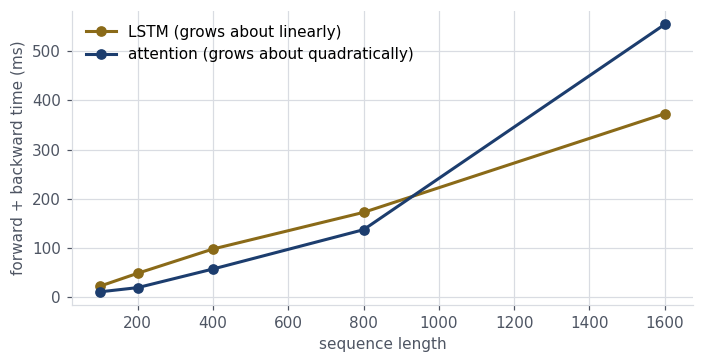

In [11]:
def best_of(fn, repeats=3):
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter(); fn(); times.append(time.perf_counter() - t0)
    return min(times)

lstm = nn.LSTM(64, 128, batch_first=True)
wq, wk, wv = nn.Linear(64, 128), nn.Linear(64, 128), nn.Linear(64, 128)
lengths = [100, 200, 400, 800, 1600]
lstm_ms, attn_ms = [], []
for T in lengths:
    xs = torch.randn(32, T, 64)
    def lstm_step():
        out, _ = lstm(xs); out.sum().backward()
    def attn_step():
        out, _ = scaled_dot_product_attention(wq(xs), wk(xs), wv(xs)); out.sum().backward()
    lstm_ms.append(best_of(lstm_step) * 1000)
    attn_ms.append(best_of(attn_step) * 1000)

print(f"{'length':>7s}{'LSTM (ms)':>11s}{'attention (ms)':>16s}{'score matrix (MB)':>19s}")
for T, a, b in zip(lengths, lstm_ms, attn_ms):
    print(f"{T:7d}{a:11.0f}{b:16.0f}{32 * T * T * 4 / 1e6:19.1f}")

plt.figure(figsize=(6.5, 3.4))
plt.plot(lengths, lstm_ms, color=AMBER, lw=2, marker="o", label="LSTM (grows about linearly)")
plt.plot(lengths, attn_ms, color=NAVY, lw=2, marker="o", label="attention (grows about quadratically)")
plt.xlabel("sequence length"); plt.ylabel("forward + backward time (ms)")
plt.legend(frameon=False); plt.tight_layout(); plt.show()

Read the shape, not the digits (the milliseconds depend on the machine). For
short sequences attention is as fast as or faster than the LSTM, because its work
can run in parallel. Each doubling of the length multiplies the LSTM time by about
two to three, but the attention time by about five at the longer lengths, and the
score matrix alone grows from about 1 MB to over 300 MB per head of a batch of 32
as the length goes from 100 to 1600. Beyond about 400 steps on this CPU, the LSTM
is the faster of the two.

That is the trade attention makes: no sequential bottleneck and no distance
penalty, in exchange for a cost that grows with the square of the sequence length.
It is the reason a great deal of later work (sparse and local attention, linear
attention, memory-efficient kernels) is about making that square smaller.

## Try it

1. Train the 12-block post-norm stack with warmup of 20 updates instead of 100.
   How short can the warmup be before training fails again?
2. Add a head-count argument: train the ViT with `n_heads = 1` and `n_heads = 8`.
   Does it change test accuracy?
3. In section 4, give the ViT 200 training images instead of 1,400. Which model
   degrades most? Does that match the "ViTs need data" argument?
4. In section 5, time attention with batch size 8 instead of 32. What happens to
   the crossover length where attention becomes slower than the LSTM?

## What this notebook showed

- A Transformer block is multi-head attention plus a position-wise feed-forward
  network, each in a residual wrapper; with the usual four-times-wider hidden layer,
  the feed-forward network holds about two thirds of the parameters.
- Normalization placement is a training-stability decision. At 12 blocks the
  post-norm layout stayed at chance without a learning-rate warmup on every seed;
  with warmup it trained, and the pre-norm layout trained either way.
- A causal mask gives exactly zero influence to later positions, and
  cross-attention is attention with queries and keys from different sequences.
- Patch embedding is a convolution with kernel size equal to stride. A tiny ViT
  learns 8 by 8 digits but does not beat a plain MLP or CNN at this data size.
- Attention removes the sequential bottleneck and the distance problem of
  recurrence at the price of a cost that grows with the square of the length.